# Part 3 · 01 EDA for safety stock & reorder point optimisation
**Goal of this notebook:** understand demand, lead times and today's reorder-point policy for the *inventory articles*
(safety_stock > 0) — independent of the classification part — and size the problem in numbers.

**Key data facts (verified below)**
- `inventory_level` is the stock **before** the transaction → we rebuild stock as opening level + cumulative movements (fixes ~160 corrupted rows, incl. one at 1.1bn units).
- Master data (`safety_stock`, `lead_time`, `moq`, `last_direct_cost`) is a **snapshot** (constant per article) → history is valued at today's price and compared against today's policy.
- All quantities incl. `safety_stock` and `moq` are scaled by the same anonymisation factor (≈1.1107) → ratios are valid.
- The company's `safety_stock` field **is used as the reorder point**.
- Demand = net sales (type 1) + usage for production (type 5). Internal transfers (4) and adjustments (2/3) are not demand.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.prep import *
pd.set_option('display.float_format', '{:,.2f}'.format)
BLUE, ORANGE, AQUA, YELLOW, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': .6,
                     'axes.edgecolor': '#b5b4ad', 'font.size': 10, 'axes.titleweight': 'bold'})
import os; FIG = '../outputs/figures'; os.makedirs(FIG, exist_ok=True)
save = lambda name: plt.savefig(f'{FIG}/{name}.png', bbox_inches='tight')

In [2]:
tx = load_transactions()
art = article_master(tx)
print(f"{len(tx):,} transactions | {art.shape[0]:,} articles | {tx.date.min():%d.%m.%Y} – {tx.date.max():%d.%m.%Y}")
print(f"Inventory articles (safety_stock > 0): {art.inv_article.sum():,}")

2,694,849 transactions | 58,764 articles | 21.01.2007 – 21.01.2022
Inventory articles (safety_stock > 0): 1,751


## 1 · Data quality & structure

In [3]:
print('Missing values:', int(tx.isna().sum().sum()))
et = {0:'Procurement',1:'Sale',2:'In adjustment',3:'Out adjustment',4:'Internal',5:'Usage for production',6:'In from production'}
q = tx.groupby('entry_type').quantity.agg(rows='size', median='median', share_positive=lambda s:(s>0).mean())
q.index = q.index.map(lambda i: f'{i} {et[i]}'); q

Missing values: 0


,rows,median,share_positive
entry_type,,,
0 Procurement,133443,11.11,0.72
1 Sale,432731,-4.44,0.03
2 In adjustment,18615,13.33,0.98
3 Out adjustment,26598,-7.78,0.00
4 Internal,115275,1.11,0.53
5 Usage for production,1748717,-8.89,0.00
6 In from production,219470,3.33,1.00


- Sales have ~3% positive rows (customer returns) and procurement ~28% negative rows (returns/corrections) → we use **net** demand per period, clipped at 0.
- Usage for production (type 5) is by far the largest movement type → most stock is consumed by production, not sold.

## 2 · Capital lockup: where is the money?

In [4]:
ia = art[art.inv_article].copy()
eod_all_ids = art.index
# daily value for inventory articles and for all articles (chunked to save memory)
eod = daily_inventory(tx, ia.index)
val_ss = eod.mul(ia.last_direct_cost.reindex(eod.columns), axis=1).sum(axis=1)
val_all = 0
for ch in np.array_split(art.index.values, 20):
    e = daily_inventory(tx, ch)
    val_all = val_all + e.mul(art.last_direct_cost.reindex(e.columns), axis=1).sum(axis=1)
use = tx[tx.is_demand].assign(v=lambda d: d.demand * d.article_nr.map(art.last_direct_cost))
use_ss = use[use.article_nr.isin(ia.index)]
yr = pd.DataFrame({'avg_stock_value_all': val_all.groupby(val_all.index.year).mean(),
                   'avg_stock_value_inv_articles': val_ss.groupby(val_ss.index.year).mean(),
                   'usage_value_inv_articles': use_ss.groupby(use_ss.date.dt.year).v.sum()}).loc[2015:2021]
yr['stock_to_usage_%'] = 100 * yr.avg_stock_value_inv_articles / yr.usage_value_inv_articles
yr['inv_articles_share_of_value_%'] = 100 * yr.avg_stock_value_inv_articles / yr.avg_stock_value_all
yr

,avg_stock_value_all,avg_stock_value_inv_articles,usage_value_inv_articles,stock_to_usage_%,inv_articles_share_of_value_%
2015,"6,440,810.78","2,076,446.44","5,675,903.12",36.58,32.24
2016,"5,186,770.85","1,754,692.31","6,700,994.56",26.19,33.83
2017,"5,995,673.79","2,408,173.81","8,418,350.21",28.61,40.17
2018,"7,363,958.21","3,517,650.53","9,898,422.26",35.54,47.77
2019,"6,952,991.84","3,649,753.42","12,613,485.41",28.94,52.49
2020,"6,940,085.13","4,112,174.92","12,224,929.78",33.64,59.25
2021,"7,816,989.37","4,884,726.49","13,088,134.55",37.32,62.49


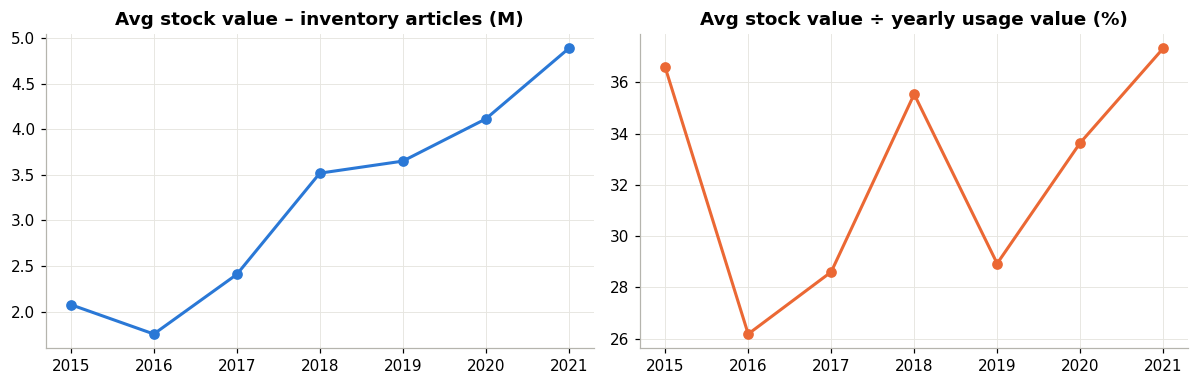

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
(yr.avg_stock_value_inv_articles/1e6).plot(ax=ax[0], color=BLUE, lw=2, marker='o')
ax[0].set_title('Avg stock value – inventory articles (M)'); ax[0].set_xlabel('')
yr['stock_to_usage_%'].plot(ax=ax[1], color=ORANGE, lw=2, marker='o')
ax[1].set_title('Avg stock value ÷ yearly usage value (%)'); ax[1].set_xlabel('')
plt.tight_layout(); save('01_lockup_trend'); plt.show()

**Read:** inventory articles are only ~3% of all articles but hold ~62% of stock value. Their average stock value rose
**+39% from 2018 to 2021** and stock-to-usage climbed from ~29% (2019) to ~37% (2021) — the same picture as the case slide
(capital lockup / revenue up ~9 pp). This is the population Part 3 must fix.

## 3 · Article-level features (last 12 / 36 months)

In [6]:
S12, S36 = END - pd.DateOffset(years=1), END - pd.DateOffset(years=3)
d12 = use_ss[use_ss.date > S12].groupby('article_nr').demand.sum().reindex(ia.index, fill_value=0).clip(lower=0)
ia['demand_12m'] = d12
ia['usage_value_12m'] = d12 * ia.last_direct_cost
e12 = eod.loc[S12 + pd.Timedelta(days=1):]
ia['avg_inv_12m'] = e12.fillna(0).mean()
ia['lockup_12m'] = ia.avg_inv_12m * ia.last_direct_cost
ia['stockout_days_12m'] = (e12 <= 1e-6).sum()
daily = (ia.demand_12m / 365).replace(0, np.nan)
ia['days_cover'] = ia.avg_inv_12m / daily
ia['lt_demand'] = daily * ia.lead_time
ia['rop_vs_lt_demand'] = ia.safety_stock / ia.lt_demand
ia['ss_vs_div4_rule'] = ia.safety_stock / (ia.demand_12m / 4).replace(0, np.nan)
ia['months_since_demand'] = (END - ia.last_demand_date).dt.days / 30.44
s = ia.usage_value_12m.sort_values(ascending=False); c = s.cumsum() / s.sum()
ia['ABC'] = pd.Series(np.select([c <= .8, c <= .95], ['A', 'B'], 'C'), index=s.index)
mon = period_demand(tx, ia.index, S36, days=30)
ia = ia.join(sbc_class(mon))
wk = period_demand(tx, ia.index, S36, days=7)
ia['spike_ratio'] = wk.max(axis=1) / wk.mean(axis=1).replace(0, np.nan)
LOCK = ia.lockup_12m.sum()
print(f'Capital lockup of inventory articles, last 12 months: {LOCK:,.0f}')

Capital lockup of inventory articles, last 12 months: 4,925,240


## 4 · Dead & slow stock (replicates slide 9)

,articles,lockup,lockup_%
months_since_demand,,,
<1 yr,1433,"4,681,456.90",95.05
1–2 yrs,52,"95,112.52",1.93
2–3 yrs,14,"5,486.06",0.11
3–5 yrs,11,"4,878.81",0.10
>5 yrs / never,241,"138,305.57",2.81


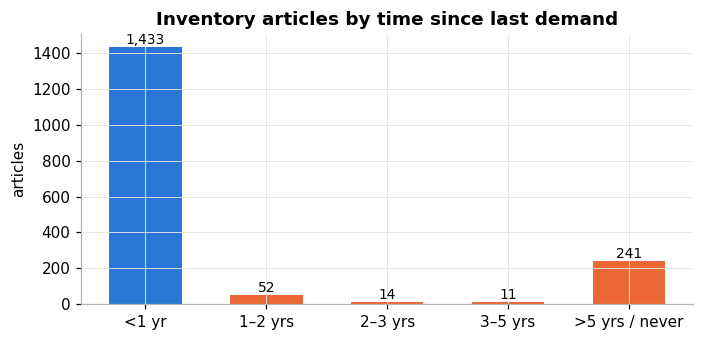

In [7]:
b = pd.cut(ia.months_since_demand.fillna(1e4), [-1, 12, 24, 36, 60, 1e5],
           labels=['<1 yr', '1–2 yrs', '2–3 yrs', '3–5 yrs', '>5 yrs / never'])
rec = ia.groupby(b, observed=False).agg(articles=('lockup_12m', 'size'), lockup=('lockup_12m', 'sum'))
rec['lockup_%'] = 100 * rec.lockup / LOCK; display(rec)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(rec.index.astype(str), rec.articles, color=[BLUE] + [ORANGE]*4, width=.6)
for i, v in enumerate(rec.articles): ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax.set_title('Inventory articles by time since last demand'); ax.set_ylabel('articles')
plt.tight_layout(); save('02_recency'); plt.show()

**Read:** 318 inventory articles (18%) still carry a reorder point but had **no demand in over a year** — 241 of them in over 5 years or never.
Their value is small (~5% of lockup), but every one triggers replenishment when stock dips: a quick win (set ROP = 0 / make-to-order).

## 5 · Demand patterns (Syntetos–Boylan, monthly buckets, last 36 months)

,articles,lockup,usage,median_spike,lockup_%,turns
demand_class,,,,,,
Smooth,166,"1,639,656.52","4,891,716.93",6.53,33.29,2.98
Erratic,373,"1,465,248.67","4,742,692.62",14.18,29.75,3.24
Lumpy,603,"1,126,533.92","2,368,971.07",34.99,22.87,2.10
Intermittent,209,"335,244.32","990,947.23",26.17,6.81,2.96
Sporadic,148,"215,372.04","77,803.85",122.11,4.37,0.36
No demand,252,"143,184.38",0.00,NaN,2.91,0.00


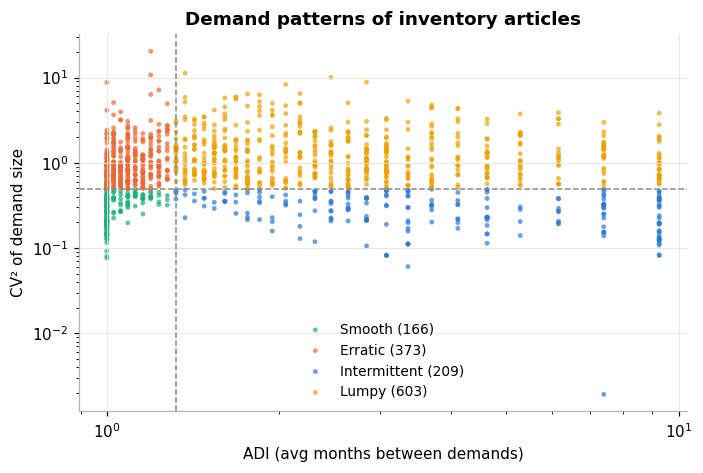

In [8]:
dc = ia.groupby('demand_class').agg(articles=('lockup_12m','size'), lockup=('lockup_12m','sum'),
                                     usage=('usage_value_12m','sum'), median_spike=('spike_ratio','median'))
dc['lockup_%'] = 100*dc.lockup/LOCK; dc['turns'] = dc.usage/dc.lockup; display(dc.sort_values('lockup', ascending=False))
fig, ax = plt.subplots(figsize=(6.5, 4.4))
m = ia.nz_periods >= 4
for cls, col in [('Smooth', AQUA), ('Erratic', ORANGE), ('Intermittent', BLUE), ('Lumpy', YELLOW)]:
    s_ = ia[m & (ia.demand_class == cls)]
    ax.scatter(s_.ADI, s_.CV2, s=10, color=col, alpha=.7, label=f'{cls} ({len(s_)})', edgecolors='none')
ax.axvline(1.32, color=GREY, ls='--', lw=1); ax.axhline(.49, color=GREY, ls='--', lw=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('ADI (avg months between demands)'); ax.set_ylabel('CV² of demand size')
ax.set_title('Demand patterns of inventory articles'); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save('03_demand_patterns'); plt.show()

**Read:** only 166 articles (~10%) have *smooth* demand — though they hold a third of lockup. ~75% are **erratic, lumpy,
intermittent or sporadic** (the case's "searched demand"); for lumpy articles the peak week is ~35× an average week (spike ratio). A plain σ-based safety stock (slide 11 formula)
will be inflated by these spikes → the solution needs spike-robust, pattern-specific methods.

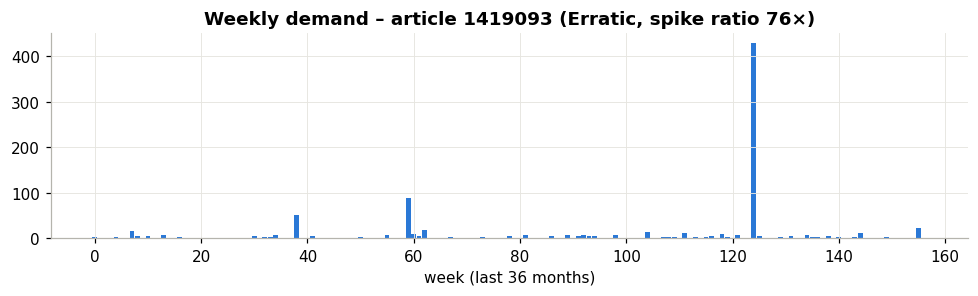

In [9]:
ex = ia[ia.nz_periods >= 12].sort_values('spike_ratio').iloc[-15]   # a typical spiky article
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(range(wk.shape[1]), wk.loc[ex.name], color=BLUE, width=.9)
ax.set_title(f'Weekly demand – article {ex.name} ({ex.demand_class}, spike ratio {ex.spike_ratio:.0f}×)')
ax.set_xlabel('week (last 36 months)'); plt.tight_layout(); save('04_spiky_example'); plt.show()

## 6 · Lead time

In [10]:
print(ia.lead_time.describe().round(1))
print(f"No lead time maintained (0): {(ia.lead_time==0).sum()} articles, "
      f"{100*ia.loc[ia.lead_time==0,'lockup_12m'].sum()/LOCK:.1f}% of lockup")
print(ia.lead_time.value_counts().head(6))

count   1,751.00
mean       26.30
std        20.70
min         0.00
25%        15.00
50%        30.00
75%        30.00
max       240.00
Name: lead_time, dtype: float64
No lead time maintained (0): 37 articles, 0.4% of lockup
lead_time
30    553
15    381
10    226
45    197
5     157
60     82
Name: count, dtype: int64


**Read:** lead time is maintained for ~98% of inventory articles, but it is clustered on round values (15 / 30 days) —
a manually set planning parameter, not a measured one. There is no order date in the data, so **lead-time variability
cannot be measured** → treat as a stated limitation and add a sensitivity check.

## 7 · Is today's reorder point linked to demand?

,articles,lockup,stockout_articles,lockup_%
rop_vs_lt_demand,,,,
<0.5×,91,"1,080,795.84",44,21.94
0.5–1×,110,"678,470.09",35,13.78
1–2×,248,"1,066,016.80",88,21.64
2–5×,361,"957,515.87",76,19.44
>5×,591,"878,068.14",43,17.83


median ROP / lead-time demand: 3.8
SS within ±20% of 'usage last 12m / 4' rule: 14% of articles


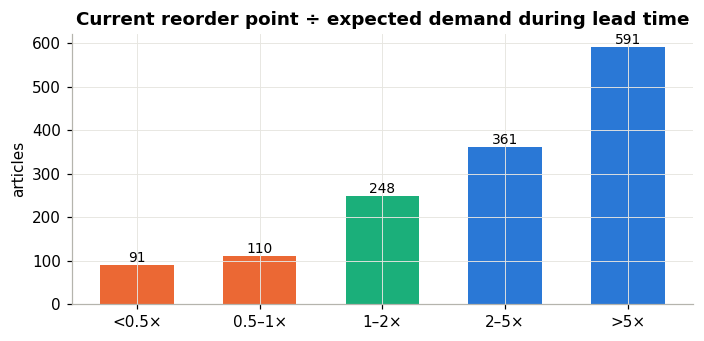

In [11]:
m = (ia.lead_time > 0) & (ia.demand_12m > 0)
r = ia.loc[m, 'rop_vs_lt_demand']
bk = pd.cut(r, [0, .5, 1, 2, 5, np.inf], labels=['<0.5×', '0.5–1×', '1–2×', '2–5×', '>5×'])
t = ia[m].groupby(bk, observed=False).agg(articles=('lockup_12m','size'), lockup=('lockup_12m','sum'),
                                          stockout_articles=('stockout_days_12m', lambda s:(s>0).sum()))
t['lockup_%'] = 100*t.lockup/LOCK; display(t)
print('median ROP / lead-time demand:', round(r.median(), 1))
r2 = ia.loc[ia.demand_12m > 0, 'ss_vs_div4_rule']
print(f"SS within ±20% of 'usage last 12m / 4' rule: {100*((r2>.8)&(r2<1.2)).mean():.0f}% of articles")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(t.index.astype(str), t.articles, color=[ORANGE, ORANGE, AQUA, BLUE, BLUE], width=.6)
for i, v in enumerate(t.articles): ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax.set_title('Current reorder point ÷ expected demand during lead time'); ax.set_ylabel('articles')
plt.tight_layout(); save('05_rop_vs_ltd'); plt.show()

**Read:** the median reorder point is **~3.8× the demand expected during the lead time**; for ~600 articles it is above 5×.
At the same time ~200 articles sit *below* lead-time demand — and these hold ~36% of lockup (high-volume articles where stock is
driven by large order quantities, not by the ROP). Only 14% of articles follow the ÷4 rule. Stock-outs happen in every bucket,
even where ROP > 5× → the ROP alone does not explain stock; ordering behaviour (order size, MOQ, spikes) matters too.
→ Today's levels are **not demand-driven**: they over-protect many articles and under-protect others.

## 8 · Over-stock and stock-outs at the same time

In [12]:
cov = pd.cut(ia.days_cover, [0, 90, 180, 365, np.inf], labels=['≤3 months', '3–6 months', '6–12 months', '>12 months'])
ct = ia.groupby(cov, observed=False).agg(articles=('lockup_12m','size'), lockup=('lockup_12m','sum'))
ct['lockup_%'] = 100*ct.lockup/LOCK; display(ct)
excess12 = ((ia.avg_inv_12m - ia.demand_12m).clip(lower=0) * ia.last_direct_cost).sum()
excess6 = ((ia.avg_inv_12m - ia.demand_12m/2).clip(lower=0) * ia.last_direct_cost).sum()
so = ia.stockout_days_12m
print(f'Median days of cover: {ia.days_cover.median():.0f} | 75th pct: {ia.days_cover.quantile(.75):.0f}')
print(f'Articles at zero stock >=1 day (last 12m): {(so>0).sum()} | >30 days: {(so>30).sum()}')
print(f'Stock value beyond 12 months of cover: {excess12:,.0f} ({100*excess12/LOCK:.0f}% of lockup)')
print(f'Stock value beyond 6 months of cover:  {excess6:,.0f} ({100*excess6/LOCK:.0f}% of lockup)')
abc = ia.groupby('ABC').agg(articles=('lockup_12m','size'), lockup=('lockup_12m','sum'),
                            median_days_cover=('days_cover','median'),
                            stockout_articles=('stockout_days_12m', lambda s:(s>0).sum()))
abc['lockup_%'] = 100*abc.lockup/LOCK; abc

,articles,lockup,lockup_%
days_cover,,,
≤3 months,377,"807,347.17",16.39
3–6 months,291,"2,055,148.48",41.73
6–12 months,291,"820,799.72",16.67
>12 months,473,"997,535.79",20.25


Median days of cover: 202 | 75th pct: 583
Articles at zero stock >=1 day (last 12m): 385 | >30 days: 155
Stock value beyond 12 months of cover: 774,492 (16% of lockup)
Stock value beyond 6 months of cover:  1,203,166 (24% of lockup)


,articles,lockup,median_days_cover,stockout_articles,lockup_%
ABC,,,,,
A,171,"3,187,077.28",85.17,49,64.71
B,304,"841,580.17",95.02,112,17.09
C,1276,"896,582.40",316.15,224,18.20


**Read:** median stock covers ~200 days (≈6.5 months) of demand; a quarter of articles hold > 1.5 years. 16% of lockup is stock
beyond 12 months of cover, 24% beyond 6 months. Yet **385 articles hit zero stock**
at least once in the last 12 months (155 for more than 30 days) — including 49 A-articles. Capital sits in the wrong articles.
171 A-articles (10%) hold ~65% of lockup → that is where the money is.

## 9 · By product type (derived from movement types)

In [13]:
pt = ia.groupby('ptype').agg(articles=('lockup_12m','size'), lockup=('lockup_12m','sum'), usage=('usage_value_12m','sum'),
                             median_days_cover=('days_cover','median'), stockout_articles=('stockout_days_12m', lambda s:(s>0).sum()))
pt['lockup_%'] = 100*pt.lockup/LOCK; pt['turns'] = pt.usage/pt.lockup; pt

,articles,lockup,usage,median_days_cover,stockout_articles,lockup_%,turns
ptype,,,,,,,
Finished (produced in-house),315,"578,163.42","2,593,048.32",75.33,135,11.74,4.48
Retail (buy & sell),336,"1,651,445.38","4,339,065.07",159.08,94,33.53,2.63
Semi-finished / component,1100,"2,695,631.05","6,140,018.30",277.53,156,54.73,2.28


Product type is not in the data, so it is derived: articles with *ingoing from production* = finished;
mainly *usage for production* = semi-finished/component; mainly *sales* = retail. Semi-finished items hold over half of lockup
with the lowest turns. Finished goods can be produced fast on site → they need little safety stock.

## 10 · Seasonality & MOQ

In [14]:
x = use_ss[(use_ss.date.dt.year >= 2015) & (use_ss.date.dt.year <= 2021)]
mo = x.groupby([x.date.dt.year, x.date.dt.month]).v.sum().unstack()
print('Month index (1 = average):', mo.div(mo.mean(axis=1), axis=0).mean().round(2).to_dict())
print(f"MOQ maintained for {100*(ia.moq>0).mean():.0f}% of inventory articles; median MOQ = {(ia.moq/ia.safety_stock)[ia.moq>0].median():.1f}× ROP")

Month index (1 = average): {1: 0.89, 2: 0.82, 3: 1.11, 4: 0.92, 5: 0.96, 6: 1.05, 7: 1.0, 8: 0.94, 9: 1.1, 10: 1.21, 11: 1.25, 12: 0.74}
MOQ maintained for 74% of inventory articles; median MOQ = 1.5× ROP


Mild seasonality (Oct–Nov peak ≈ +20%, Dec dip) → a rolling 12-month demand window absorbs it; no need for a seasonal model.
MOQs are large relative to the reorder point → part of the stock is **cycle stock driven by MOQ**, not safety stock; the
simulation must respect MOQ so savings are not overstated.

## 11 · EDA conclusions → design of the solution
| Finding | Implication for the Part 3 solution |
|---|---|
| Inventory articles hold ~62% of stock value; lockup +39% 2018→21 | Focus on these 1,751 articles; baseline = last 12 months lockup |
| ROP median 3.8× lead-time demand, not linked to demand; only 14% follow ÷4 rule | Recalculate ROP from demand × lead time + safety stock |
| 385 articles had stock-outs while 16–24% of value is excess cover | Re-allocate: cut where over-covered, raise where under-covered |
| ~75% of articles non-smooth, big spikes | Pattern-specific methods; spike-robust σ / empirical quantiles; Croston/SBA for intermittent |
| A-articles = 65% of lockup | Service level by value class (ABC) — biggest € lever |
| 318 articles with no demand > 1 yr | Quick win: ROP → 0, run down / make-to-order |
| Lead time = manual, no variability measurable | Sensitivity analysis on lead time (+/- 50%) |
| MOQ large vs ROP | Simulate with MOQ to report honest savings |

In [15]:
ia.to_parquet('../outputs/eda_article_features.parquet')